# Lab 7 · Example A — IMDB Sentiment with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Goal.** Read a movie review and classify it as **positive** or **negative** (binary). You will
turn text into integer indices, pad them, learn **word embeddings**, summarise each review with a
**Bidirectional LSTM**, and decide with a **sigmoid** output.

---
Replace every `None  # TODO (Qn)` with the correct value/code. Run top to bottom.
*(Needs internet once to download the IMDB dataset — works on Colab.)*


## Step 0 — Imports *(given)*

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Load and pad the data

IMDB reviews come **already encoded as integer indices**. Keep the top `num_words` words and pad
every review to `maxlen` tokens.

*Hints:* keep the 10000 most frequent words; pad to length 200.


In [3]:
# Q1a) hyperparameters
num_words = 1000     # TODO (Q1a): keep the 10000 most frequent words
maxlen    = 200     # TODO (Q1a): fix every review to 200 tokens

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=num_words)

# Q1b) pad both sets to a fixed length
X_train = pad_sequences(X_train, maxlen=maxlen)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=maxlen)   # TODO (Q1b): maxlen

# Q1c) hold out 20% of training data for validation
X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42)   # TODO (Q1c): 0.2

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (20000, 200)  X_val: (5000, 200)  X_test: (25000, 200)


#### Quick check *(given)*

In [4]:
assert X_train.shape[1] == 200, "reviews should be padded to length 200"
assert set(np.unique(y_train)) <= {0, 1}, "labels should be binary (0/1)"
print("Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)")

Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)


## Task 2 — Build the model

Stack: **Embedding** (vocabulary `num_words`, 128-dim vectors) → **Bidirectional LSTM(64)**
returning a single summary vector → **Dropout(0.5)** → **Dense(1, sigmoid)**.

*Hints:* `Embedding(input_dim=num_words, output_dim=128)`; a bidirectional LSTM that returns one
vector uses `return_sequences=False`; one output neuron with a sigmoid gives a probability.


In [5]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding: vocabulary size -> 128-dim word vectors
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM with 64 units, returning ONE summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

# Q2c) Dropout to reduce overfitting
model.add(Dropout(0.5))   # TODO (Q2c): 0.5

# Q2d) Output: one neuron, sigmoid (positive/negative probability)
model.add(Dense(1, activation='sigmoid'))   # TODO (Q2d): 1, 'sigmoid'

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │       128,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,945 (886.50 KB)

 Trainable params: 226,945 (886.50 KB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2e.** The Embedding layer shows **1,280,000** parameters. Show why with
`num_words × embed_dim`. Why does this one layer hold most of the model's parameters?

> **Your answer (Q2e):** 1,280,000 = 1000 × 128 ; it dominates because .


## Task 3 — Compile and train

Use the **adam** optimiser, **binary crossentropy** loss (one sigmoid output), track accuracy.
Train 5 epochs, batch size 64, validating on `(X_val, y_val)`.


In [6]:
# Q3a) compile for binary classification
model.compile(optimizer='adam',
              loss='binary_crossentropy',              # TODO (Q3a): 'binary_crossentropy'
              metrics=['accuracy'])

# Q3b) train
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=5,          # TODO (Q3b): 5
                    batch_size=64)      # TODO (Q3b): 64

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 25ms/step - accuracy: 0.7289 - loss: 0.5203 - val_accuracy: 0.7230 - val_loss: 0.5400
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.8283 - loss: 0.3988 - val_accuracy: 0.8088 - val_loss: 0.4436
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.8361 - loss: 0.3836 - val_accuracy: 0.8402 - val_loss: 0.3831
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.8632 - loss: 0.3290 - val_accuracy: 0.8516 - val_loss: 0.3636
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.8706 - loss: 0.3135 - val_accuracy: 0.8490 - val_loss: 0.3614


## Task 4 — Evaluate and plot *(fill the blanks)*

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8524 - loss: 0.3519
Test accuracy: 85.24%


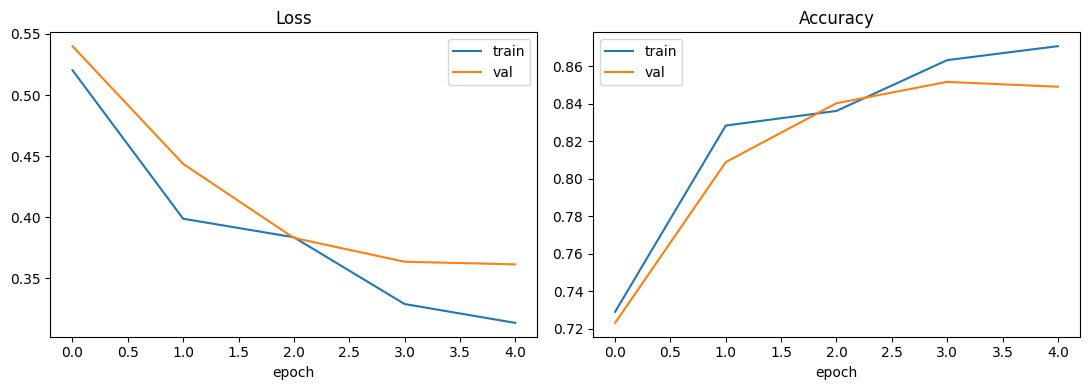

In [8]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 86-88%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

## Task 5 — Predict on your own text *(fill the blanks)*

IMDB reserves indices 0–2 (pad / start / unknown), so real words are **offset by 3**.


In [9]:
word_index = imdb.get_word_index()

def predict_sentiment(review):
    enc = [word_index.get(w, 0) + 3 for w in review.lower().split()]
    padded = pad_sequences([enc], maxlen=maxlen)
    p = model.predict(padded, verbose=0)[0][0]
    # Q5) threshold the sigmoid at 0.5
    return "Positive" if p >= 0.5 else "Negative"   # TODO (Q5): 0.5

for r in ["this film was absolutely wonderful and moving",
          "a boring dull waste of time"]:
    print(f"{predict_sentiment(r):8s} <- {r}")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Positive <- this film was absolutely wonderful and moving
Negative <- a boring dull waste of time


## Task 6 — Short questions *(write answers here)*

1. Why do we **pad** every review to the same length?
2. What does the **Embedding** layer do that one-hot encoding of words would not?
3. Why `return_sequences=False` here (unlike the music lab)?
4. Why `sigmoid` + `binary_crossentropy` instead of `softmax` + `categorical_crossentropy`?
5. In your accuracy plot, does validation loss start rising? What does that indicate, and what
   does `Dropout(0.5)` do about it?

> **Your answers:**
1. **Padding** ensures all input sequences have a uniform shape, which is required to process them in efficient, parallelized mini-batches during neural network training.
2. The **Embedding** layer maps high-dimensional sparse word indices to low-dimensional, dense continuous vector spaces where semantic relationships and word similarities are learned and preserved (unlike sparse, orthogonal one-hot vectors).
3. We set `return_sequences=False` because we are performing a **sequence-to-vector** task (sentiment classification of the whole review) where we only need the final hidden state summarizing the entire sequence, rather than step-by-step outputs.
4. We use `sigmoid` + `binary_crossentropy` because this is a **binary classification** task (positive vs. negative sentiment) with a single output neuron predicting probability. Softmax with categorical crossentropy is designed for multi-class classification.
5. Yes, validation loss begins to level out or rise slightly while training loss continues to drop, which indicates **overfitting**. `Dropout(0.5)` randomly deactivates 50% of neurons during training to prevent co-adaptation, forcing the model to learn more robust, generalizable features.